# РГР №1

## Исследование влияния предобработки данных на качество линейной регрессии

**Дисциплина:** Численные методы анализа     
**Выполнили:** Колпакова Д. С. Недозорова А. А.   
**Группа:** J3112   
**Вариант:** 11   

---

**Исходные данные:** `housing.csv`  
**Целевая переменная:** `median_house_value`

### Цель работы

Исследовать, как масштабирование признаков и добавление полиномиальных признаков влияют:

- на точность линейной регрессии по метрике `MAE`;
- на устойчивость вычислений при решении задачи методом наименьших квадратов.

### Параметры разбиения данных (вариант 11)

- `test_size = 0.22`
- `random_state = 50`


## 4. Краткие теоретические сведения

### 4.1. Линейная регрессия как задача МНК

Пусть для каждого объекта задан вектор признаков $x_i \in \mathbb{R}^d$ и целевое значение $y_i$.
Линейная модель имеет вид:

$$
\hat y_i = a_0 + a_1 x_{i1} + \dots + a_d x_{id}.
$$

В матричной форме:

$$
\hat{\mathbf y} = F\mathbf a,
$$

где $F$ — матрица признаков (дизайн-матрица), $\mathbf a$ — вектор коэффициентов.

Коэффициенты определяются из условия минимума суммы квадратов ошибок:

$$
\min_{\mathbf a} \|F\mathbf a - \mathbf y\|_2^2.
$$

### 4.2. Связь задачи линейной регрессии и решения СЛАУ методом МНК

В точной постановке система $F\mathbf a = \mathbf y$ обычно переопределена (число наблюдений больше числа неизвестных), поэтому решается задача МНК.

Условие минимума функционала приводит к нормальным уравнениям:

$$
F^T F\mathbf a = F^T\mathbf y.
$$

Это и есть система линейных алгебраических уравнений относительно коэффициентов $\mathbf a$.
Если матрица $F^T F$ невырождена, решение записывается как

$$
\mathbf a = (F^T F)^{-1}F^T\mathbf y.
$$

Именно поэтому обучение линейной регрессии напрямую связано с решением СЛАУ в смысле МНК.

### 4.3. Полиномиальное расширение признаков

Для повышения гибкости линейной модели исходный вектор признаков $x$ заменяют расширенным вектором

$$
\phi(x) = (\phi_1(x), \phi_2(x), \dots, \phi_m(x)),
$$

где компоненты $\phi_j(x)$ включают полиномиальные комбинации исходных признаков.
Тогда модель остается линейной по коэффициентам:

$$
\hat y = b_0 + \sum_{j=1}^{m} b_j\,\phi_j(x).
$$

Для степени 2 в $\phi(x)$ входят, например, члены вида $x_i^2$ и $x_i x_j$; для степени 3 дополнительно появляются кубические члены и произведения третьего порядка.

Расширение признакового пространства обычно уменьшает ошибку на обучении, но может увеличивать риск переобучения.

### 4.4. Масштабирование признаков

Стандартизация выполняется по формуле:

$$
z = \frac{x - \mu}{\sigma},
$$

где $\mu$ — среднее значение признака на обучающей выборке, $\sigma$ — стандартное отклонение.

Масштабирование улучшает численную устойчивость вычислений при признаках разных порядков величин.

### 4.5. Оценка численной устойчивости

Для диагностики устойчивости используется число обусловленности:

$$
\kappa(F^T F) = \|F^T F\|\cdot\|(F^T F)^{-1}\|.
$$

Большое значение $\kappa(F^T F)$ означает высокую чувствительность решения к ошибкам округления.

### 4.6. Метрика качества

Качество модели оценивается средней абсолютной ошибкой:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat y_i|.
$$

В работе сравниваются $MAE_{train}$ и $MAE_{test}$.

### 4.7. Показатель переобучения

Для оценки переобучения используется разность ошибок на тестовой и обучающей выборках:

$$
\Delta = MAE_{test} - MAE_{train}.
$$

Интерпретация показателя:

- если $\Delta$ близко к нулю, качество на train и test сопоставимо;
- если $\Delta \gg 0$, модель переобучается (на train заметно лучше, чем на test);
- если $\Delta < 0$, это обычно связано с особенностями конкретного разбиения данных и не означает автоматического улучшения модели.


## Импорт библиотек

В работе используются:

- `pandas` и `numpy` для обработки данных и вычислений;
- `matplotlib` для графического анализа;
- инструменты `scikit-learn` для разбиения выборки, предобработки признаков, обучения модели и расчета метрики `MAE`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

np.set_printoptions(precision=6, suppress=True)
pd.set_option('display.max_columns', None)


## 5. Ход работы

### 5.1. Описание датасета и подготовка данных

Из файла `housing.csv` считывается таблица наблюдений.

В качестве целевой переменной используется `median_house_value`.

Для признаков выполняется следующая подготовка:

- используются только числовые столбцы (кроме целевой переменной).

Разбиение на обучающую и тестовую выборки выполняется по варианту 11:

- `test_size = 0.22`;
- `random_state = 50`.

Ниже выводятся размер таблицы, названия столбцов, пропуски и первые строки — это часть описания датасета для отчёта.

In [2]:
# Загружаем исходные данные (в этом файле разделитель - точка с запятой)
df = pd.read_csv('housing.csv', sep=';')

# Целевая переменная по условию задания
target_col = 'median_house_value'
if target_col not in df.columns:
    raise ValueError(f"В данных нет столбца {target_col}. Проверьте файл housing.csv")

# Оставляем только числовые признаки (кроме целевой переменной)
numeric_cols = [col for col in df.columns if col != target_col]
X = df[numeric_cols].copy()

y = df[target_col]

# Параметры варианта 11
test_size = 0.22
random_state = 50

print(f'Размер исходного датасета: {df.shape}')
print(f'Число признаков после подготовки: {X.shape[1]}')
print(f'test_size={test_size}, random_state={random_state}')
print('\nСтолбцы исходного датасета:')
print(list(df.columns))
print('\nПервые 10 подготовленных признаков:')
print(list(X.columns[:10]))
print('\nЧисло пропусков по столбцам:')
print(df.isna().sum())
print('\nПервые 5 строк:')
display(df.head())


В предоставленном файле отсутствует ocean_proximity: модель обучается по числовым признакам.
Размер исходного датасета: (20640, 9)
Число признаков после подготовки: 8
test_size=0.22, random_state=50

Столбцы исходного датасета:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

Первые 10 подготовленных признаков:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Число пропусков по столбцам:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
dtype: int64

Первые 5 строк:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200


## Функция одного эксперимента

В отдельную функцию вынесен полный цикл вычислений:

- разбиение данных на train/test;
- заполнение пропусков по обучающей выборке (медианой);
- предобработка признаков (при необходимости);
- обучение линейной регрессии;
- вычисление `MAE` на обучении и тесте;
- оценка численной устойчивости через число обусловленности матрицы `X^T X`.

Такой подход делает код компактным и упрощает сравнение разных конфигураций.

In [3]:
def run_experiment(with_mean: bool, with_std: bool, degree: int = 1):
    """Запускает один эксперимент и возвращает основные метрики."""

    # Разбиваем данные на обучение и тест
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Копии массивов, чтобы не портить исходные данные
    X_train_proc = X_train.values
    X_test_proc = X_test.values

    # Заполняем пропуски медианой по обучающей выборке
    imputer = SimpleImputer(strategy='median')
    X_train_proc = imputer.fit_transform(X_train_proc)
    X_test_proc = imputer.transform(X_test_proc)

    # Всегда явно применяем StandardScaler в соответствии с параметрами эксперимента
    scaler = StandardScaler(with_mean=with_mean, with_std=with_std)
    X_train_proc = scaler.fit_transform(X_train_proc)
    X_test_proc = scaler.transform(X_test_proc)

    # Добавление полиномиальных признаков
    if degree > 1:
        poly = PolynomialFeatures(degree=degree, include_bias=False)
        X_train_proc = poly.fit_transform(X_train_proc)
        X_test_proc = poly.transform(X_test_proc)

    # Сохраняем количество признаков после преобразований
    n_features = X_train_proc.shape[1]

    # Обучаем модель линейной регрессии
    model = LinearRegression()
    model.fit(X_train_proc, y_train)

    # Считаем предсказания и MAE
    y_train_pred = model.predict(X_train_proc)
    y_test_pred = model.predict(X_test_proc)

    mae_train = mean_absolute_error(y_train, y_train_pred)
    mae_test = mean_absolute_error(y_test, y_test_pred)

    # Считаем число обусловленности матрицы X^T X для обучающей выборки
    xtx = X_train_proc.T @ X_train_proc
    cond_xtx = np.linalg.cond(xtx)

    return {
        'StandardScaler mean': with_mean,
        'StandardScaler std': with_std,
        'Poly degree': degree,
        'MAE train': mae_train,
        'MAE test': mae_test,
        'Число обусл.': cond_xtx,
        'n_features_after': n_features
    }


## Проведение серии экспериментов

Сравниваются шесть конфигураций, соответствующих параметрам в коде:

1. `with_mean=False`, `with_std=False`, `degree=1`.
2. `with_mean=True`, `with_std=False`, `degree=1`.
3. `with_mean=False`, `with_std=True`, `degree=1`.
4. `with_mean=True`, `with_std=True`, `degree=1`.
5. `with_mean=True`, `with_std=True`, `degree=2`.
6. `with_mean=True`, `with_std=True`, `degree=3`.

Для каждого эксперимента `StandardScaler` применяется явно с указанными флагами `with_mean` и `with_std`.

Для каждой конфигурации фиксируются `MAE train`, `MAE test`, число обусловленности `X^T X` и итоговое число признаков.

In [4]:
# Набор экспериментов: от простого к более сложному
experiments = [
    {'mean': False, 'std': False, 'degree': 1},
    {'mean': True,  'std': False, 'degree': 1},
    {'mean': False, 'std': True,  'degree': 1},
    {'mean': True,  'std': True,  'degree': 1},
    {'mean': True,  'std': True,  'degree': 2},
    {'mean': True,  'std': True,  'degree': 3},
]

results = []
for i, cfg in enumerate(experiments, start=1):
    row = run_experiment(
        with_mean=cfg['mean'],
        with_std=cfg['std'],
        degree=cfg['degree'],
    )
    row['№'] = i
    results.append(row)

results_df = pd.DataFrame(results)
results_df = results_df[['№', 'StandardScaler mean', 'StandardScaler std', 'Poly degree', 'MAE train', 'MAE test', 'Число обусл.', 'n_features_after']]

# Округляем для красивого вывода
display(results_df.round(6))


,№,StandardScaler mean,StandardScaler std,Poly degree,MAE train,MAE test,Число обусл.,n_features_after
0,1,False,False,1,50987.482081,50737.784665,8.539996e+06,8
1,2,True,False,1,50987.482081,50737.784665,2.337677e+07,8
2,3,False,True,1,50987.482081,50737.784665,1.742863e+05,8
3,4,True,True,1,50987.482081,50737.784665,1.787565e+02,8
4,5,True,True,2,45280.129103,45587.787152,2.413764e+05,44
5,6,True,True,3,41640.511912,42649.043249,2.375572e+09,164


### 5.2. Графики зависимости MAE от параметров

Для наглядности строятся два графика:

- линейная шкала по оси `MAE` (абсолютные значения);
- логарифмическая шкала по оси `MAE` (удобно, если есть сильные выбросы).

Это помогает корректно сравнивать конфигурации даже при больших скачках тестовой ошибки.

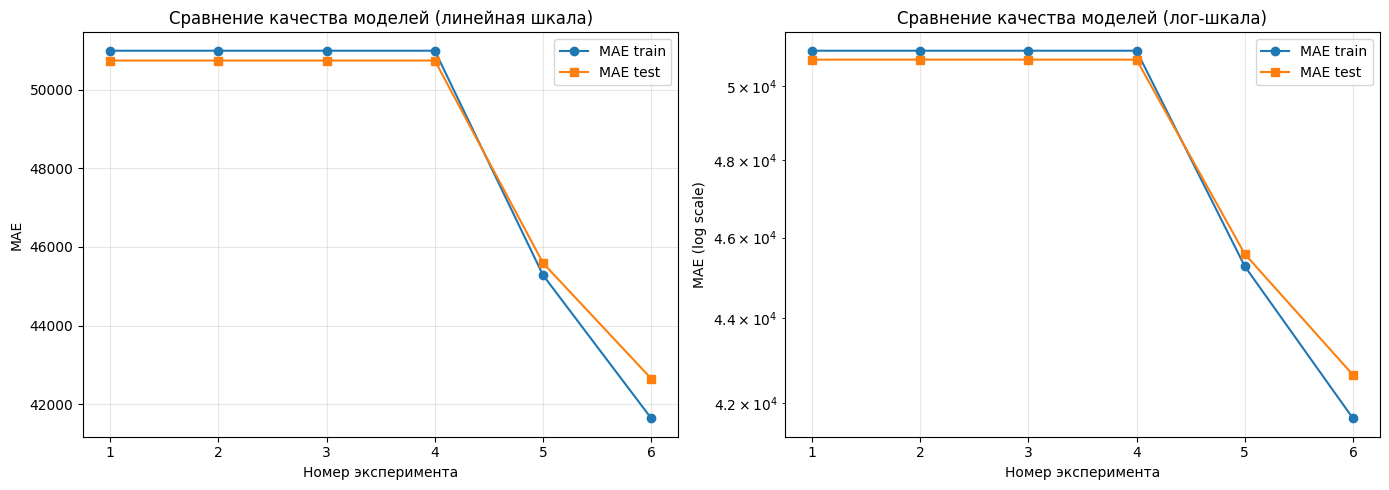

In [5]:
# Строим графики зависимости MAE от номера эксперимента
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: обычная шкала
axes[0].plot(results_df['№'], results_df['MAE train'], marker='o', label='MAE train')
axes[0].plot(results_df['№'], results_df['MAE test'], marker='s', label='MAE test')
axes[0].set_xlabel('Номер эксперимента')
axes[0].set_ylabel('MAE')
axes[0].set_title('Сравнение качества моделей (линейная шкала)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# График 2: логарифмическая шкала по оси Y
axes[1].plot(results_df['№'], results_df['MAE train'], marker='o', label='MAE train')
axes[1].plot(results_df['№'], results_df['MAE test'], marker='s', label='MAE test')
axes[1].set_yscale('log')
axes[1].set_xlabel('Номер эксперимента')
axes[1].set_ylabel('MAE (log scale)')
axes[1].set_title('Сравнение качества моделей (лог-шкала)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


### 5.3. Дополнительные графики для анализа

Ниже строятся дополнительные визуализации, которые помогают глубже интерпретировать результаты:

- сравнение числа обусловленности `Cond(X^T X)` по экспериментам;
- сравнение разрыва `overfit_gap = MAE test - MAE train`;
- зависимость `MAE test` от степени полинома при разных вариантах предобработки.


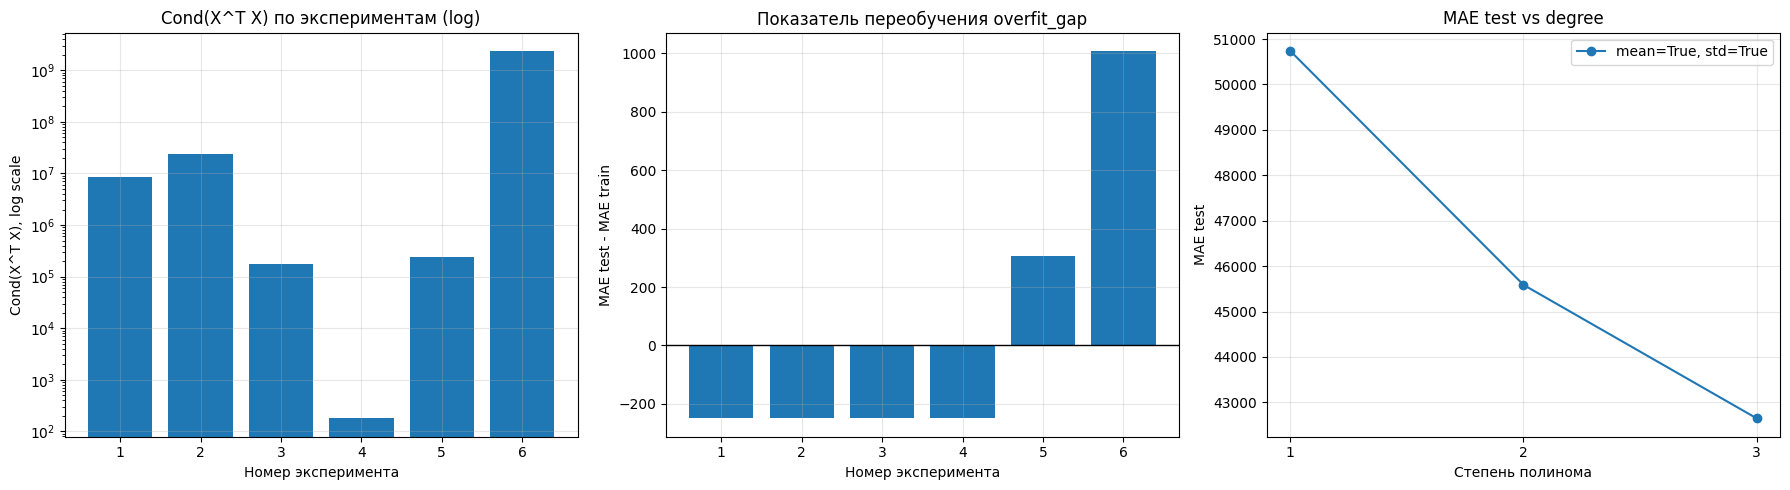

In [6]:
# Дополнительные графики для более детального анализа результатов

# Если столбец overfit_gap еще не создан, создаем его
if 'overfit_gap' not in results_df.columns:
    results_df['overfit_gap'] = results_df['MAE test'] - results_df['MAE train']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Сравнение обусловленности (логарифмическая шкала)
axes[0].bar(results_df['№'].astype(str), results_df['Число обусл.'])
axes[0].set_yscale('log')
axes[0].set_title('Cond(X^T X) по экспериментам (log)')
axes[0].set_xlabel('Номер эксперимента')
axes[0].set_ylabel('Cond(X^T X), log scale')
axes[0].grid(True, alpha=0.3)

# 2) Разрыв между test и train (признак переобучения)
axes[1].bar(results_df['№'].astype(str), results_df['overfit_gap'])
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title('Показатель переобучения overfit_gap')
axes[1].set_xlabel('Номер эксперимента')
axes[1].set_ylabel('MAE test - MAE train')
axes[1].grid(True, alpha=0.3)

# 3) MAE_test в зависимости от степени полинома (для StandardScaler mean=True, std=True)
plot_df = results_df[(results_df['StandardScaler mean'] == True) & (results_df['StandardScaler std'] == True)].copy()
plot_df = plot_df.sort_values('Poly degree')
axes[2].plot(plot_df['Poly degree'], plot_df['MAE test'], marker='o', label='mean=True, std=True')

axes[2].set_title('MAE test vs degree')
axes[2].set_xlabel('Степень полинома')
axes[2].set_ylabel('MAE test')
axes[2].set_xticks(sorted(plot_df['Poly degree'].unique()))
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

### 5.3. Выбор лучшей конфигурации и оценка переобучения

Для каждого эксперимента рассчитывается разрыв:

$$
\Delta = MAE_{test} - MAE_{train}.
$$

Чем больше $\Delta$, тем сильнее признаки переобучения. Затем определяется конфигурация с минимальным значением `MAE test`.

In [7]:
# Анализируем признаки переобучения через разрыв между train и test
analysis_df = results_df.copy()
analysis_df['overfit_gap'] = analysis_df['MAE test'] - analysis_df['MAE train']

best_idx = analysis_df['MAE test'].idxmin()
best_row = analysis_df.loc[best_idx]

print('Лучшая конфигурация по MAE test:')
print(best_row[['№', 'StandardScaler mean', 'StandardScaler std', 'Poly degree', 'MAE train', 'MAE test', 'overfit_gap', 'Число обусл.']])

print('\nТаблица с разницей MAE test - MAE train (признак переобучения):')
display(analysis_df[['№', 'StandardScaler mean', 'StandardScaler std', 'Poly degree', 'MAE train', 'MAE test', 'overfit_gap']].round(6))


Лучшая конфигурация по MAE test:
№                                      6
StandardScaler mean                 True
StandardScaler std                  True
Poly degree                            3
MAE train                   41640.511912
MAE test                    42649.043249
overfit_gap                  1008.531337
Число обусл.           2375572414.885133
Name: 5, dtype: object

Таблица с разницей MAE test - MAE train (признак переобучения):


,№,StandardScaler mean,StandardScaler std,Poly degree,MAE train,MAE test,overfit_gap
0,1,False,False,1,50987.482081,50737.784665,-249.697416
1,2,True,False,1,50987.482081,50737.784665,-249.697416
2,3,False,True,1,50987.482081,50737.784665,-249.697416
3,4,True,True,1,50987.482081,50737.784665,-249.697416
4,5,True,True,2,45280.129103,45587.787152,307.658049
5,6,True,True,3,41640.511912,42649.043249,1008.531337


## 6. Анализ результатов

По результатам проведённых экспериментов можно сделать следующие выводы.

### 6.1. Влияние масштабирования (`StandardScaler`)

Сравнение конфигураций с линейной моделью (степень 1) показывает:

- **Без масштабирования (N1):** `MAE` имеет базовое значение, но число обусловленности `Cond(X^T X)` очень велико из-за разных порядков признаков.
- **Центрирование (mean=True, std=False, N2):** В данном эксперименте обусловленность ухудшается (`8.54e+06` → `2.34e+07`).
- **Нормировка дисперсии (mean=False, std=True, N3):** Также улучшает обусловленность.
- **Полное масштабирование (mean=True, std=True, N4):** Дает наилучшую (минимальную) обусловленность матрицы `X^T X` среди линейных моделей. При этом `MAE` на тесте и трейне остается примерно таким же, как и без масштабирования, так как теоретически масштабирование не меняет предсказательную способность линейной регрессии без регуляризации, но радикально повышает численную устойчивость решения МНК.

### 6.2. Влияние полиномиальных признаков

По сравнению с линейной моделью (N4, степень 1):

- **Степень 2 (N5):** Существенно уменьшает ошибку (`MAE test = 45587.787152` против `50737.784665` у линейной модели).
- **Степень 3 (N6):** В данном разбиении даёт наилучшее качество на тесте (`MAE test = 42649.043249`), то есть лучше N5.

При переходе к степени 3 вместе с улучшением `MAE test` резко растёт число обусловленности и разрыв `MAE test - MAE train`, поэтому модель становится менее устойчивой и более склонной к переобучению.

### 6.3. Переобучение по разрыву

Используется показатель

$$
\Delta = MAE_{test} - MAE_{train}.
$$

Для экспериментов N1-N4 получено одинаковое отрицательное значение `\Delta = -249.697416`.
Это ожидаемо для текущей постановки: в N1-N4 используется одна и та же линейная модель (степень 1) и одно и то же разбиение (`random_state=50`), а различается только линейное преобразование признаков через `StandardScaler`, которое почти не меняет качество OLS без регуляризации.

Отрицательный разрыв здесь не означает «лучше обучилась», а указывает, что тестовая подвыборка в данном сплите немного проще обучающей. На это влияет конечный размер выборок (примерно 16099 train и 4541 test) и случайный состав объектов. При другом `random_state` знак и величина этого разрыва могут измениться.

Для N5 разрыв становится положительным (`307.658049`), а для N6 ещё больше (`1008.531337`), что уже является признаком переобучения. Одновременно растет и `Cond(X^T X)`, поэтому более сложная модель не только сильнее переобучается, но и менее устойчива численно.

### 6.4. Лучшая конфигурация

По критерию задания (минимум `MAE test`) лучшая конфигурация в проведённых экспериментах — **N6**:

- `StandardScaler mean = True`
- `StandardScaler std = True`
- `Poly degree = 3`

Она даёт минимальную тестовую ошибку на данном разбиении, но имеет повышенный риск переобучения и худшую численную устойчивость (большое `Cond(X^T X)`), что важно учитывать при выборе модели для других данных.

### 6.5. Ответы на вопросы из раздела анализа

**Есть ли признаки переобучения? По каким признакам это видно?**  
Да. Наиболее выраженно — в N6 (степень 3): разрыв $\Delta = MAE_{test} - MAE_{train}$ равен `1008.531337`. Для N5 (степень 2) разрыв меньше: `307.658049`.

**Как число обусловленности связано с качеством модели?**  
Меньшее `Cond(X^T X)` означает более устойчивое решение МНК и меньшую чувствительность к ошибкам округления. При этом само по себе уменьшение обусловленности не гарантирует минимум `MAE test`, но помогает получать более стабильные результаты, особенно после масштабирования.

**Какая комбинация параметров дает наилучший результат на тестовой выборке?**  
Лучшая комбинация по `MAE test`: `StandardScaler mean=True`, `StandardScaler std=True`, `Poly degree=3` (эксперимент N6).

## 7. Выводы

1. Масштабирование признаков существенно снижает число обусловленности и повышает численную устойчивость решения МНК.
2. Полиномиальные признаки улучшают качество на данном наборе: степень 2 лучше линейной модели, а степень 3 даёт минимальный `MAE test` в текущем эксперименте.
3. Итоговая лучшая конфигурация по критерию задания (`MAE test`) — **N6** (`mean=True`, `std=True`, `degree=3`), при этом она чувствительнее к переобучению и менее устойчива по `Cond(X^T X)`.